# Tarea 2. Modelación y Simulación de Procesos Estocásticos
## Un parque eólico en Huazamota, Mezquital, Durango: Markov, eventos discretos y Monte Carlo

**Universidad Juárez del Estado de Durango (UJED)**  

**Facultad de Ciencias Exactas · Maestría en Estadística Aplicada**  

**Asignatura:** Simulación Estocástica  

**Docente:** Dr. Gerónimo Quiñónez-Barraza

**Alumna:** Angeles Sarahí Vargas Gutiérrez

---

## Resumen

Se estudia un parque eólico de varias turbinas con tres técnicas de simulación que se complementan: (1) una **cadena de Markov** para el viento, con sus propiedades analíticas (distribución estacionaria, duración de los estados, convergencia); (2) una **simulación de eventos discretos** de las fallas y reparaciones de las turbinas, con una cola para las cuadrillas de mantenimiento, validada contra la teoría de colas; y (3) un **experimento Monte Carlo** que combina ambos procesos para estimar la energía anual del parque, con intervalos de confianza, para Huazamota (Mezquital, Durango).

**Cómo usarlo:** ejecútalo de principio a fin (*Entorno de ejecución → Ejecutar todo*). Los datos de viento se descargan solos.

## 1. Planteamiento

**Pregunta.** ¿Cuánta energía produce al año un parque de 10 turbinas en Huazamota cuando se consideran tanto la variabilidad del viento como las fallas de las turbinas, y cuánto cambia el resultado con 1 o 2 cuadrillas de mantenimiento?

**Objetivos.**
1. Modelar el viento como cadena de Markov y verificar sus propiedades (estacionariedad, duración de los estados, convergencia) y su supuesto de primer orden.
2. Simular con eventos discretos las fallas y reparaciones del parque y validar la simulación contra la solución analítica del modelo de *población finita con servidores* (machine repairman).
3. Estimar por Monte Carlo el factor de capacidad y la energía anual del parque, con intervalos de confianza y pruebas de hipótesis para comparar escenarios.

**Alcance.** Se estudia un solo sitio, Huazamota, con datos horarios de viento de NASA POWER (2023-2026). Los parámetros de falla y reparación son **supuestos didácticos**, no datos de un parque real.

## 2. Configuración

Todos los supuestos están en esta celda.

- **Sitio:** Huazamota, en el municipio de Mezquital, Durango (cañada del río Huazamota, a unos 600 m de altitud). Para cambiarlo, edita `LOCALIDADES` en la celda siguiente.
- **Viento:** NASA POWER a 50 m, extrapolado a 80 m con ley de potencia (exponente 1/7).
- **Aerogenerador genérico:** arranque a 3 m/s, potencia nominal a 12 m/s, corte a 25 m/s.
- **Parque:** 10 turbinas con el mismo viento (sin efecto estela). Cada turbina falla con tiempo exponencial de media `MTBF_H` mientras opera y se repara en un tiempo exponencial de media `MTTR_H`. Las cuadrillas atienden en orden de llegada.

In [1]:
import os, re, time, heapq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 42
rng = np.random.default_rng(SEED)

# ----- Periodo de datos de viento
ANIO_INI, ANIO_FIN = 2023, 2026
FECHA_ULTIMO_DATO = None          # None = hoy menos 7 días; o una fecha, p. ej. "2026-10-31"

# ----- Localidades (latitud, longitud aproximadas)
LOCALIDADES = {
    "Huazamota (Mezquital, Dgo.)": {"lat": 22.525, "lon": -104.498},   # INEGI: 22°31'30" N, 104°29'48" O
}
PARAMETRO = "WS50M"
ALTURA_BASE, ALTURA_BUJE, ALFA = 50.0, 80.0, 1/7

# ----- Aerogenerador genérico (m/s)
V_ARRANQUE, V_NOMINAL, V_CORTE = 3.0, 12.0, 25.0

# ----- Cadena de Markov: estados por velocidad (m/s)
BORDES_ESTADOS = [0, 3, 6, 9, 12, np.inf]
NOMBRES_ESTADOS = ["Calma", "Baja", "Moderada", "Alta", "Muy alta"]
K = len(NOMBRES_ESTADOS)

# ----- Parque y mantenimiento (supuestos didácticos)
N_TURB = 10                       # turbinas del parque
MTBF_H = 1000.0                   # horas medias entre fallas de una turbina que opera
MTTR_H = 48.0                     # horas medias de reparación
N_CUADRILLAS = [1, 2]             # escenarios de cuadrillas de mantenimiento

# ----- Simulación
N_SIM = 1000                      # réplicas Monte Carlo (años simulados)
HORAS_ANIO = 8760
CF_UMBRAL = 0.30                  # factor de capacidad de referencia

COLORES = dict(zip(LOCALIDADES, ["tab:blue", "tab:orange"]))

## 3. Datos de viento: NASA POWER

Se descargan series **horarias** de viento a 50 m (un año por solicitud) y se guardan en la carpeta `datos_nasa_power` para no repetir la descarga. Provienen de reanálisis (MERRA-2): cada punto representa una celda de unos 50 km y no captura el relieve local.

In [2]:
URL_NASA = "https://power.larc.nasa.gov/api/temporal/hourly/point"
CARPETA_CACHE = "datos_nasa_power"
os.makedirs(CARPETA_CACHE, exist_ok=True)

if FECHA_ULTIMO_DATO is None:
    FECHA_FIN_DATOS = pd.Timestamp.today().normalize() - pd.Timedelta(days=7)
else:
    FECHA_FIN_DATOS = pd.Timestamp(FECHA_ULTIMO_DATO)
FECHA_FIN_DATOS = min(FECHA_FIN_DATOS, pd.Timestamp(f"{ANIO_FIN}-12-31"))


def descargar_nasa_power(lat, lon, anio_ini, anio_fin, fecha_fin, parametro=PARAMETRO, reintentos=3):
    """Serie horaria de NASA POWER, un año por solicitud, hasta fecha_fin."""
    partes = []
    for anio in range(anio_ini, anio_fin + 1):
        inicio = pd.Timestamp(f"{anio}-01-01")
        fin = min(pd.Timestamp(f"{anio}-12-31"), fecha_fin)
        if fin < inicio:
            continue
        params = {"parameters": parametro, "community": "RE", "longitude": lon, "latitude": lat,
                  "start": inicio.strftime("%Y%m%d"), "end": fin.strftime("%Y%m%d"), "format": "JSON"}
        for intento in range(reintentos):
            try:
                r = requests.get(URL_NASA, params=params, timeout=180)
                r.raise_for_status()
                datos_anio = r.json()["properties"]["parameter"][parametro]
                break
            except Exception as e:
                if intento == reintentos - 1:
                    raise RuntimeError(f"Falló la descarga de {anio}: {e}")
                time.sleep(5)
        s = pd.Series(datos_anio, dtype=float)
        s.index = pd.to_datetime(s.index, format="%Y%m%d%H")
        partes.append(s)
    serie = pd.concat(partes).sort_index()
    return serie.where(serie > -990)               # -999 = dato faltante


def cargar_serie(nombre, lat, lon):
    archivo = os.path.join(CARPETA_CACHE, re.sub(r"\W+", "_", nombre)
                           + f"_{PARAMETRO}_{lat:.3f}_{lon:.3f}_{ANIO_INI}_{FECHA_FIN_DATOS:%Y%m%d}.csv")
    if os.path.exists(archivo):
        return pd.read_csv(archivo, index_col=0, parse_dates=True).iloc[:, 0]
    print(f"Descargando {nombre} ...")
    s = descargar_nasa_power(lat, lon, ANIO_INI, ANIO_FIN, FECHA_FIN_DATOS)
    s.to_csv(archivo)
    return s


datos, V = {}, {}
for nombre, c in LOCALIDADES.items():
    s50 = cargar_serie(nombre, c["lat"], c["lon"])
    s50 = s50.interpolate(limit=6, limit_area="inside").dropna()
    df = pd.DataFrame({"v50": s50})
    df["v"] = df["v50"] * (ALTURA_BUJE / ALTURA_BASE) ** ALFA      # viento a la altura del buje
    df["mes"] = df.index.month
    datos[nombre], V[nombre] = df, df["v"].to_numpy()
    print(f"{nombre}: {len(df):,} horas ({df.index.min():%Y-%m-%d} a {df.index.max():%Y-%m-%d}); "
          f"viento medio a 80 m: {df['v'].mean():.2f} m/s")


def potencia_normalizada(v):
    """Potencia de un aerogenerador genérico (fracción de la nominal)."""
    p = np.zeros(v.shape, dtype=float)
    m1 = (v >= V_ARRANQUE) & (v < V_NOMINAL)
    p[m1] = (v[m1] ** 3 - V_ARRANQUE ** 3) / (V_NOMINAL ** 3 - V_ARRANQUE ** 3)
    p[(v >= V_NOMINAL) & (v < V_CORTE)] = 1.0
    return p

Descargando Huazamota (Mezquital, Dgo.) ...
Huazamota (Mezquital, Dgo.): 33,648 horas (2023-01-01 a 2026-11-02); viento medio a 80 m: 2.78 m/s


## 4. Parte 1: cadena de Markov del viento

El viento se discretiza en $K=5$ estados (calma, baja, moderada, alta, muy alta) y se estima la matriz de transición de un paso (una hora) con $p_{ij}=n_{ij}/n_{i\cdot}$. Con esa matriz se pueden obtener propiedades **analíticas** y compararlas con lo que ocurre en los datos y en la simulación:

- **Distribución estacionaria** $\pi$, que cumple $\pi P=\pi$: la fracción de tiempo a largo plazo en cada estado.
- **Duración esperada de una racha** en el estado $i$: como la permanencia es geométrica, $E[D_i]=1/(1-p_{ii})$ horas.
- **Velocidad de convergencia:** con qué rapidez $\pi_0 P^n$ se acerca a $\pi$ (la determina el segundo valor propio de $P$).

Además se contrasta el **supuesto de primer orden** (que, conocido el estado actual, el pasado no aporta información) con una prueba de razón de verosimilitud $G$ sobre ternas consecutivas de estados.

In [3]:
def discretizar(v):
    return np.digitize(v, BORDES_ESTADOS[1:-1])        # estados 0..K-1


def matriz_transicion(est):
    C = np.zeros((K, K))
    np.add.at(C, (est[:-1], est[1:]), 1)
    f = C.sum(axis=1, keepdims=True)
    P = np.divide(C, f, out=np.zeros_like(C), where=f > 0)
    for i in np.where(f.ravel() == 0)[0]:              # estado sin datos: absorbente
        P[i, i] = 1.0
    return P


def estacionaria(P, activos):
    """Distribución estacionaria sobre los estados con datos (los demás reciben probabilidad 0)."""
    a = np.where(activos)[0]
    w, vec = np.linalg.eig(P[np.ix_(a, a)].T)
    x = np.real(vec[:, np.argmin(np.abs(w - 1))])
    pi = np.zeros(K)
    pi[a] = x / x.sum()
    return pi


def rachas(mascara):
    """Duraciones (horas) de las rachas consecutivas de True."""
    m = np.asarray(mascara, int)
    d = np.diff(np.concatenate(([0], m, [0])))
    return np.where(d == -1)[0] - np.where(d == 1)[0]


def simular_trayectoria(P, n, rng, i0=0):
    """Trayectoria de n pasos por transformada inversa discreta."""
    cum = np.cumsum(P, axis=1)
    cum[:, -1] = 1.0
    u = rng.random(n)
    est = np.empty(n, dtype=np.int8)
    est[0] = i0
    for t in range(1, n):
        est[t] = np.searchsorted(cum[est[t - 1]], u[t])
    return est


EST, P_GLOBAL, PI, ACTIVOS = {}, {}, {}, {}
for nombre, v in V.items():
    EST[nombre] = discretizar(v)
    ACTIVOS[nombre] = np.bincount(EST[nombre][:-1], minlength=K) > 0       # estados con datos
    P_GLOBAL[nombre] = matriz_transicion(EST[nombre])
    PI[nombre] = estacionaria(P_GLOBAL[nombre], ACTIVOS[nombre])
    print(f"\nMatriz de transición horaria: {nombre}")
    display(pd.DataFrame(P_GLOBAL[nombre], index=NOMBRES_ESTADOS, columns=NOMBRES_ESTADOS).round(3))


Matriz de transición horaria: Huazamota (Mezquital, Dgo.)


,Calma,Baja,Moderada,Alta,Muy alta
Calma,0.914,0.086,0.000,0.000,0.0
Baja,0.165,0.799,0.036,0.000,0.0
Moderada,0.000,0.269,0.728,0.003,0.0
Alta,0.000,0.000,0.455,0.545,0.0
Muy alta,0.000,0.000,0.000,0.000,1.0


In [4]:
N_TRAY = 200_000
filas = []
for nombre in V:
    P, est, pi = P_GLOBAL[nombre], EST[nombre], PI[nombre]
    tray = simular_trayectoria(P, N_TRAY, rng, i0=int(np.argmax(ACTIVOS[nombre])))
    pi_sim = np.bincount(tray, minlength=K) / N_TRAY
    for k, estado in enumerate(NOMBRES_ESTADOS):
        r_obs = rachas(est == k)
        r_sim = rachas(tray == k)
        filas.append({"Localidad": nombre, "Estado": estado,
                      "π empírica": np.mean(est == k), "π estacionaria": pi[k], "π simulada": pi_sim[k],
                      "Duración teórica 1/(1-pii) (h)": 1 / (1 - P[k, k]) if ACTIVOS[nombre][k] and P[k, k] < 1 else np.nan,
                      "Duración observada (h)": r_obs.mean() if len(r_obs) else np.nan,
                      "Duración simulada (h)": r_sim.mean() if len(r_sim) else np.nan})
display(pd.DataFrame(filas).set_index(["Localidad", "Estado"]).round(3))

π empírica  π estacionaria  π simulada  \
Localidad                   Estado                                             
Huazamota (Mezquital, Dgo.) Calma          0.627           0.627       0.624   
                            Baja           0.328           0.328       0.330   
                            Moderada       0.044           0.044       0.045   
                            Alta           0.000           0.000       0.000   
                            Muy alta       0.000           0.000       0.000   

                                      Duración teórica 1/(1-pii) (h)  \
Localidad                   Estado                                     
Huazamota (Mezquital, Dgo.) Calma                             11.623   
                            Baja                               4.975   
                            Moderada                           3.671   
                            Alta                               2.200   
                            Muy alta                             NaN   

                                      Duración observada (h)  \
Localidad                   Estado                             
Huazamota (Mezquital, Dgo.) Calma                     11.617   
                            Baja                       4.975   
                            Moderada                   3.671   
                            Alta                       2.200   
                            Muy alta                     NaN   

                                      Duración simulada (h)  
Localidad                   Estado                           
Huazamota (Mezquital, Dgo.) Calma                    11.553  
                            Baja                      4.967  
                            Moderada                  3.606  
                            Alta                      2.273  
                            Muy alta                    NaN

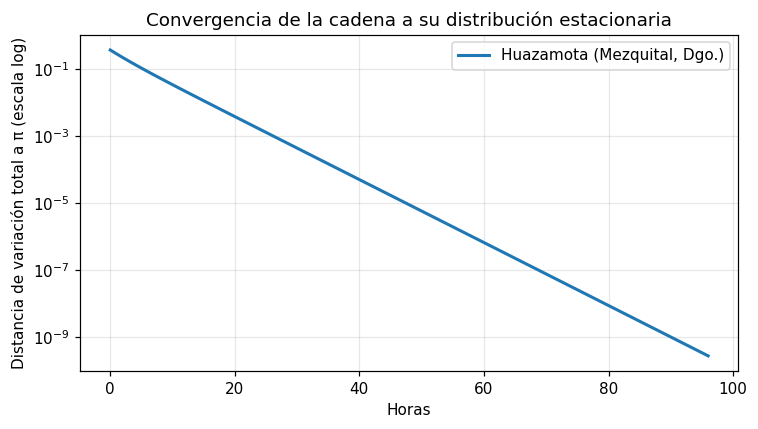

,|λ2|,Horas para distancia < 0.01,G (orden 1 vs 2),gl,valor p
Localidad,,,,,
"Huazamota (Mezquital, Dgo.)",0.8052,16,717.311,10,0.0


In [5]:
# Convergencia a la distribución estacionaria y prueba del supuesto de primer orden
def distancia_vt(a, b):
    return 0.5 * np.abs(a - b).sum()


def prueba_markov_orden1(est):
    """H0: dado el estado actual, el anterior no influye en el siguiente (razón de verosimilitud G)."""
    n = np.zeros((K, K, K))
    np.add.at(n, (est[:-2], est[1:-1], est[2:]), 1)
    G, gl = 0.0, 0
    for j in range(K):
        t = n[:, j, :]
        if t.sum() == 0:
            continue
        r, c = t.sum(1, keepdims=True), t.sum(0, keepdims=True)
        esp = r * c / t.sum()
        m = t > 0
        G += 2 * np.sum(t[m] * np.log(t[m] / esp[m]))
        gl += (np.sum(r > 0) - 1) * (np.sum(c > 0) - 1)
    return G, gl, stats.chi2.sf(G, gl)


fig, ax = plt.subplots(figsize=(7, 4))
filas = []
for nombre in V:
    P, pi = P_GLOBAL[nombre], PI[nombre]
    p = np.zeros(K); p[np.argmax(ACTIVOS[nombre])] = 1.0      # se parte del estado más bajo con datos
    dist = []
    for n in range(0, 97):
        dist.append(distancia_vt(p, pi))
        p = p @ P
    ax.semilogy(dist, color=COLORES[nombre], lw=2, label=nombre)
    a = np.where(ACTIVOS[nombre])[0]
    lam2 = np.sort(np.abs(np.linalg.eigvals(P[np.ix_(a, a)])))[-2]
    n_mezcla = next((n for n, d in enumerate(dist) if d < 0.01), None)
    G, gl, pv = prueba_markov_orden1(EST[nombre])
    filas.append({"Localidad": nombre, "|λ2|": lam2,
                  "Horas para distancia < 0.01": n_mezcla,
                  "G (orden 1 vs 2)": G, "gl": gl, "valor p": pv})
ax.set_xlabel("Horas"); ax.set_ylabel("Distancia de variación total a π (escala log)")
ax.set_title("Convergencia de la cadena a su distribución estacionaria"); ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(filas).set_index("Localidad").round(4))

### Interpretación

**Estacionariedad.** La distribución estacionaria coincide con la empírica y con la de la trayectoria simulada de 200,000 horas: calma 0.627 (empírica y estacionaria) y 0.624 (simulada), baja 0.328 y 0.330, moderada 0.044 y 0.045. La coincidencia entre la empírica y la estacionaria es esperable, porque la matriz se estimó con esos mismos datos; la verificación real es la simulada, que reproduce las fracciones de tiempo y confirma que la simulación por transformada inversa está bien implementada. En Huazamota el viento a 80 m (media de 2.78 m/s) pasa casi dos de cada tres horas en el estado de calma (menos de 3 m/s, es decir, por debajo de la velocidad de arranque de la turbina), una tercera parte en viento bajo (3 a 6 m/s) y apenas 4.4% del tiempo (unas 1,500 de las 33,648 horas) en viento moderado. Los estados de viento alto y muy alto casi no se visitan; el estado "muy alto" no tiene ninguna observación y por eso se marca como `NaN` y su fila de la matriz solo es un marcador.

**Duración de las rachas.** La duración teórica $1/(1-p_{ii})$ coincide con la observada y con la simulada: 11.6 h en calma (11.623, 11.617 y 11.553), 5.0 h en viento bajo y 3.7 h en moderado. Las rachas de calma son las más largas porque la probabilidad de permanecer en ese estado es la más alta ($p_{11}=0.914$), así que una vez que el viento cae por debajo de 3 m/s tarda en promedio casi 12 horas en volver a subir. Para un aerogenerador eso significa periodos continuos sin producción de varias horas, no interrupciones aisladas.

**Convergencia.** El segundo valor propio es $|\lambda_2|=0.805$ y la distancia a $\pi$ baja de 0.01 en 16 horas, por lo que la cadena "olvida" su estado inicial en menos de un día. La gráfica es una recta en escala logarítmica, como corresponde a una convergencia geométrica de razón $|\lambda_2|$. Esto describe al modelo, no necesariamente al viento real.

**Supuesto de primer orden.** La prueba $G$ da 717.3 con 10 grados de libertad y un valor $p$ menor a 0.001, así que se rechaza que el estado de la hora anterior no aporte información una vez conocido el estado actual. Con más de 33,000 observaciones la prueba detecta incluso desviaciones pequeñas, por lo que conviene leerla junto con la magnitud del efecto; aun así, es coherente con lo que ya se vio en el proyecto final: un modelo de primer orden subestima la persistencia de varias horas y el ciclo diario del viento. Se mantiene como modelo razonable para estimar promedios anuales, pero no para reproducir la dinámica fina.

## 5. Parte 2: simulación de eventos discretos de las fallas del parque

El parque es un sistema con **población finita y servidores limitados**: $N$ turbinas que fallan (tasa $\lambda=1/\text{MTBF}$ por turbina que opera) y $c$ cuadrillas que las reparan (tasa $\mu=1/\text{MTTR}$ por cuadrilla). Si todas las cuadrillas están ocupadas, la turbina averiada **espera en cola**.

La simulación avanza de evento en evento con una **lista de eventos** (cola de prioridad por tiempo): `falla` y `fin de reparación`. Para cada año simulado se obtiene el perfil horario de disponibilidad del parque (fracción de turbinas operando).

**Validación analítica.** Con tiempos exponenciales, el número de turbinas averiadas $n$ es un proceso de nacimiento y muerte con tasa de nacimiento $(N-n)\lambda$ y de muerte $\min(n,c)\mu$, cuya distribución estacionaria es

$$p_n \propto \prod_{k=1}^{n}\frac{(N-k+1)\lambda}{\min(k,c)\,\mu}.$$

De ahí salen la disponibilidad esperada, la utilización de las cuadrillas y el tiempo medio de espera (con la ley de Little), que se comparan con los de la simulación.

In [6]:
def simular_parque(n_turb, n_cuad, horas, rng, mtbf, mttr):
    """Eventos discretos de un parque con cola de reparación (FIFO).
    Devuelve el perfil horario de disponibilidad del parque y estadísticas del año."""
    ev = []                                              # lista de eventos: (tiempo, tipo, turbina); 0 = falla, 1 = fin de reparación
    for i in range(n_turb):
        heapq.heappush(ev, (rng.exponential(mtbf), 0, i))
    libres, cola = n_cuad, []
    inicio_falla = [0.0] * n_turb
    abajo = set()
    disp = np.ones((n_turb, horas))                      # fracción de cada hora en que opera
    esperas, fallas, ocupado = [], 0, 0.0

    def registrar(i, a, b):
        a_h, b_h = int(a), min(int(np.ceil(b)), horas)
        h = np.arange(a_h, b_h)
        disp[i, a_h:b_h] -= np.minimum(b, h + 1) - np.maximum(a, h)

    def iniciar_servicio(t, i):
        nonlocal ocupado
        d = rng.exponential(mttr)
        ocupado += min(t + d, horas) - t
        heapq.heappush(ev, (t + d, 1, i))

    while ev:
        t, tipo, i = heapq.heappop(ev)
        if t >= horas:
            break
        if tipo == 0:                                    # falla
            fallas += 1; inicio_falla[i] = t; abajo.add(i)
            if libres > 0:
                libres -= 1; esperas.append(0.0); iniciar_servicio(t, i)
            else:
                cola.append((i, t))
        else:                                            # fin de reparación
            registrar(i, inicio_falla[i], t); abajo.discard(i)
            heapq.heappush(ev, (t + rng.exponential(mtbf), 0, i))
            if cola:
                j, tf = cola.pop(0)
                esperas.append(t - tf); iniciar_servicio(t, j)
            else:
                libres += 1
    for i in abajo:                                      # turbinas que siguen averiadas al terminar el año
        registrar(i, inicio_falla[i], horas)
    return disp.mean(axis=0).astype(np.float32), fallas, esperas, ocupado / (n_cuad * horas)


def teoria_poblacion_finita(N, c, mtbf, mttr):
    """Solución estacionaria exacta del modelo de N máquinas y c reparadores (exponencial)."""
    lam, mu = 1 / mtbf, 1 / mttr
    p = [1.0]
    for n in range(1, N + 1):
        p.append(p[-1] * (N - n + 1) * lam / (min(n, c) * mu))
    p = np.array(p) / np.sum(p)
    n = np.arange(N + 1)
    operando = N - np.sum(n * p)
    tasa_fallas = lam * operando                         # fallas por hora del parque
    lq = np.sum(np.maximum(n - c, 0) * p)
    return {"disp": operando / N, "util": np.sum(np.minimum(n, c) * p) / c,
            "espera": lq / tasa_fallas, "fallas_turb_anio": tasa_fallas * HORAS_ANIO / N}


def ic_media(x, conf=0.95):
    m, h = np.mean(x), stats.sem(x) * stats.t.ppf((1 + conf) / 2, len(x) - 1)
    return m, m - h, m + h


DISP, filas = {}, []
for c in N_CUADRILLAS:
    perfiles = np.empty((N_SIM, HORAS_ANIO), dtype=np.float32)
    n_fallas, esperas_tot, util = [], [], []
    for r in range(N_SIM):
        perfiles[r], nf, w, u = simular_parque(N_TURB, c, HORAS_ANIO, rng, MTBF_H, MTTR_H)
        n_fallas.append(nf); esperas_tot += w; util.append(u)
    DISP[c] = perfiles
    disp_r = perfiles.mean(axis=1)
    m, lo, hi = ic_media(disp_r)
    t = teoria_poblacion_finita(N_TURB, c, MTBF_H, MTTR_H)
    filas.append({"Cuadrillas": c,
                  "Disponibilidad simulada": m, "IC 95%": f"({lo:.4f}, {hi:.4f})", "Disponibilidad teórica": t["disp"],
                  "Utilización simulada": np.mean(util), "Utilización teórica": t["util"],
                  "Espera media simulada (h)": np.mean(esperas_tot), "Espera media teórica (h)": t["espera"],
                  "Fallas/turbina-año simuladas": np.mean(n_fallas) / N_TURB, "Fallas/turbina-año teóricas": t["fallas_turb_anio"]})
display(pd.DataFrame(filas).set_index("Cuadrillas").round(4).T)

Cuadrillas,1,2
Disponibilidad simulada,0.9296,0.9525
IC 95%,"(0.9286, 0.9307)","(0.9520, 0.9530)"
Disponibilidad teórica,0.9283,0.9525
Utilización simulada,0.4404,0.2289
Utilización teórica,0.4456,0.2286
Espera media simulada (h),28.1421,1.7858
Espera media teórica (h),29.2329,1.8484
Fallas/turbina-año simuladas,8.1486,8.3859
Fallas/turbina-año teóricas,8.1319,8.3441


### Interpretación

**Validación.** Con 2 cuadrillas la disponibilidad simulada (0.9525, IC 95%: 0.9520 a 0.9530) coincide con la teórica (0.9525), y con 1 cuadrilla la simulada (0.9296, IC: 0.9286 a 0.9307) queda a solo 0.0013 de la teórica (0.9283), que cae apenas por debajo del intervalo. Esa diferencia es mínima y tiene una explicación clara: cada año simulado empieza con las 10 turbinas operando, por lo que el sistema tarda unas decenas de horas en llegar al régimen estacionario y, durante ese arranque, la cola está vacía. Eso concuerda con que la utilización (0.440 frente a 0.446) y la espera media (28.1 h frente a 29.2 h) simuladas sean un poco menores que las teóricas, y con que las fallas por turbina-año sean un poco mayores (8.15 frente a 8.13 con 1 cuadrilla, y 8.39 frente a 8.34 con 2). En conjunto, la simulación de eventos discretos reproduce la solución analítica del modelo de población finita y se considera validada.

**Efecto de las cuadrillas.** Pasar de 1 a 2 cuadrillas sube la disponibilidad del parque de 0.930 a 0.953 (2.3 puntos porcentuales) y reduce la espera media por una cuadrilla de unas 28 horas a menos de 2. Como el tiempo medio de reparación es de 48 h, una turbina averiada permanece fuera de servicio unas 76 h con 1 cuadrilla y unas 50 h con 2. La segunda cuadrilla ayuda aunque la primera esté ocupada menos de la mitad del tiempo (utilización de 0.44), porque las fallas llegan al azar y a veces se juntan varias: esos momentos de congestión forman la cola, y con 2 cuadrillas la utilización baja a 0.23 y casi no hay espera.

## 6. Parte 3: Monte Carlo del parque completo

Se simulan `N_SIM` años del parque combinando los dos procesos, que son independientes entre sí:

1. El **viento horario** de Huazamota se genera con una cadena de Markov con ciclo mensual (una matriz por mes, con ventana móvil de tres meses) y las velocidades se obtienen remuestreando velocidades reales del mismo estado, como en el proyecto final.
2. La **disponibilidad** horaria del parque viene de la simulación de eventos discretos de la Parte 2.

En cada réplica el **factor de capacidad del parque** es
$$CF=\frac{1}{8760}\sum_{t=1}^{8760} P\big(v_t\big)\,A_t,$$
donde $P(v_t)$ es la potencia normalizada de la turbina y $A_t$ la fracción de turbinas disponibles en la hora $t$. La energía anual por MW instalado es $CF\times 8760$ MWh. Con las réplicas se estima la media, su intervalo de confianza de 95% con la distribución $t$ y la probabilidad de superar el umbral `CF_UMBRAL`, con intervalo de Wilson.

In [7]:
def ventana_meses(m):
    return [(m - 2) % 12 + 1, m, m % 12 + 1]               # mes anterior, actual y siguiente (circular)


def matrices_mensuales(est, mes):
    """Una matriz de transición por mes (ventana móvil de 3 meses)."""
    Pg = matriz_transicion(est)
    Cg = np.zeros((K, K)); np.add.at(Cg, (est[:-1], est[1:]), 1)
    fg = Cg.sum(axis=1)
    P = np.zeros((12, K, K))
    for m in range(1, 13):
        idx = np.where(np.isin(mes[:-1], ventana_meses(m)))[0]
        C = np.zeros((K, K)); np.add.at(C, (est[idx], est[idx + 1]), 1)
        f = C.sum(axis=1, keepdims=True)
        Pm = np.divide(C, f, out=np.zeros_like(C), where=f > 0)
        vacias = np.where(f.ravel() == 0)[0]
        Pm[vacias] = Pg[vacias]
        P[m - 1] = Pm
    return P


def simular_cadena_mensual(P, mes_horas, n_sim, rng, pi0):
    cum = np.cumsum(P, axis=2)
    cum[:, :, -1] = 1.0
    n = len(mes_horas)
    est = np.empty((n_sim, n), dtype=np.int8)
    est[:, 0] = rng.choice(K, size=n_sim, p=pi0)
    for t in range(1, n):
        u = rng.random(n_sim)
        est[:, t] = (u[:, None] > cum[mes_horas[t - 1] - 1][est[:, t - 1]]).sum(axis=1)
    return est


def estados_a_velocidad(est, mes_horas, v_real, est_real, mes_real, rng):
    """Velocidad continua: remuestreo de velocidades reales del mismo estado en la ventana de meses."""
    out = np.empty(est.shape)
    for m in range(1, 13):
        cols = mes_horas == m
        if not cols.any():
            continue
        sub = est[:, cols]
        res = np.empty(sub.shape)
        en_ventana = np.isin(mes_real, ventana_meses(m))
        for k in range(K):
            mascara = sub == k
            if not mascara.any():
                continue
            reserva = v_real[(est_real == k) & en_ventana]
            if len(reserva) < 20:
                reserva = v_real[est_real == k]
            res[mascara] = rng.choice(reserva, size=int(mascara.sum()))
        out[:, cols] = res
    return out


MES_ANIO = pd.date_range("2001-01-01", periods=HORAS_ANIO, freq="h").month.to_numpy()   # año de 8,760 horas

CF, CF_IDEAL = {}, {}
for nombre, v in V.items():
    mes = datos[nombre]["mes"].to_numpy()
    M = matrices_mensuales(EST[nombre], mes)
    en_enero = EST[nombre][mes == 1]
    pi0 = np.bincount(en_enero, minlength=K) / len(en_enero)
    est_sim = simular_cadena_mensual(M, MES_ANIO, N_SIM, rng, pi0)
    v_sim = estados_a_velocidad(est_sim, MES_ANIO, v, EST[nombre], mes, rng)
    Pot = potencia_normalizada(v_sim).astype(np.float32)
    CF_IDEAL[nombre] = Pot.mean(axis=1)                                   # parque sin fallas
    for c in N_CUADRILLAS:
        CF[(nombre, c)] = (Pot * DISP[c]).mean(axis=1)                    # parque con fallas
    del est_sim, v_sim, Pot
    print(f"{nombre}: {N_SIM} años simulados")

Huazamota (Mezquital, Dgo.): 1000 años simulados


In [8]:
filas = []
for nombre in V:
    m0, lo0, hi0 = ic_media(CF_IDEAL[nombre])
    filas.append({"Localidad": nombre, "Escenario": "Sin fallas", "CF medio": m0, "IC 95%": f"({lo0:.4f}, {hi0:.4f})",
                  "Energía (MWh/MW·año)": m0 * HORAS_ANIO, "P(CF ≥ umbral)": np.mean(CF_IDEAL[nombre] >= CF_UMBRAL),
                  "IC 95% de la probabilidad": "", "Pérdida por fallas (%)": 0.0})
    for c in N_CUADRILLAS:
        x = CF[(nombre, c)]
        m, lo, hi = ic_media(x)
        k = int((x >= CF_UMBRAL).sum())
        ci = stats.binomtest(k, len(x)).proportion_ci(method="wilson")
        filas.append({"Localidad": nombre, "Escenario": f"{c} cuadrilla(s)", "CF medio": m, "IC 95%": f"({lo:.4f}, {hi:.4f})",
                      "Energía (MWh/MW·año)": m * HORAS_ANIO, "P(CF ≥ umbral)": k / len(x),
                      "IC 95% de la probabilidad": f"({ci.low:.3f}, {ci.high:.3f})",
                      "Pérdida por fallas (%)": 100 * (1 - m / m0)})
display(pd.DataFrame(filas).set_index(["Localidad", "Escenario"]).round(4))

CF medio            IC 95%  \
Localidad                   Escenario                                    
Huazamota (Mezquital, Dgo.) Sin fallas        0.0172  (0.0171, 0.0173)   
                            1 cuadrilla(s)    0.0160  (0.0159, 0.0161)   
                            2 cuadrilla(s)    0.0164  (0.0163, 0.0165)   

                                            Energía (MWh/MW·año)  \
Localidad                   Escenario                              
Huazamota (Mezquital, Dgo.) Sin fallas                150.797195   
                            1 cuadrilla(s)            140.274597   
                            2 cuadrilla(s)            143.657700   

                                            P(CF ≥ umbral)  \
Localidad                   Escenario                        
Huazamota (Mezquital, Dgo.) Sin fallas                 0.0   
                            1 cuadrilla(s)             0.0   
                            2 cuadrilla(s)             0.0   

                                           IC 95% de la probabilidad  \
Localidad                   Escenario                                  
Huazamota (Mezquital, Dgo.) Sin fallas                                 
                            1 cuadrilla(s)            (0.000, 0.004)   
                            2 cuadrilla(s)            (0.000, 0.004)   

                                            Pérdida por fallas (%)  
Localidad                   Escenario                               
Huazamota (Mezquital, Dgo.) Sin fallas                      0.0000  
                            1 cuadrilla(s)                  6.9780  
                            2 cuadrilla(s)                  4.7345

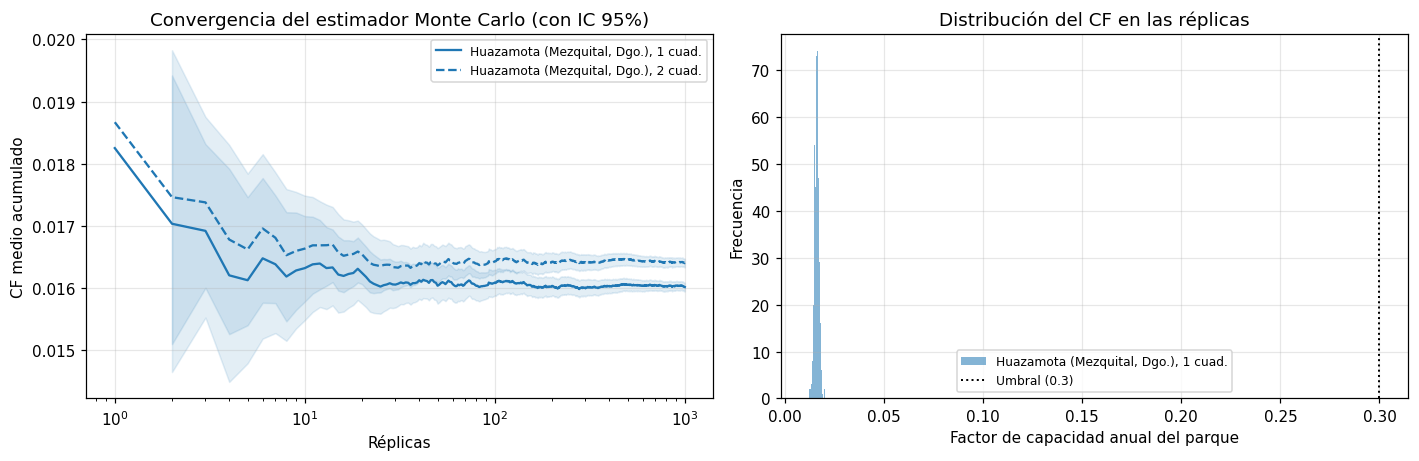

In [9]:
# Convergencia del estimador Monte Carlo y distribución del CF
fig, axs = plt.subplots(1, 2, figsize=(13, 4.3))
n = np.arange(1, N_SIM + 1)
estilos = {1: "-", 2: "--"}
for nombre in V:
    for c in N_CUADRILLAS:
        x = CF[(nombre, c)]
        media = np.cumsum(x) / n
        sd = np.array([np.std(x[:i], ddof=1) if i > 1 else np.nan for i in n])
        h = 1.96 * sd / np.sqrt(n)
        axs[0].plot(n, media, estilos.get(c, ":"), color=COLORES[nombre], lw=1.5, label=f"{nombre}, {c} cuad.")
        axs[0].fill_between(n, media - h, media + h, color=COLORES[nombre], alpha=0.12)
axs[0].set_xscale("log"); axs[0].set_xlabel("Réplicas"); axs[0].set_ylabel("CF medio acumulado")
axs[0].set_title("Convergencia del estimador Monte Carlo (con IC 95%)"); axs[0].legend(fontsize=8)

for nombre in V:
    axs[1].hist(CF[(nombre, N_CUADRILLAS[0])], bins=40, alpha=0.55, color=COLORES[nombre], label=f"{nombre}, {N_CUADRILLAS[0]} cuad.")
axs[1].axvline(CF_UMBRAL, color="k", ls=":", lw=1.3, label=f"Umbral ({CF_UMBRAL})")
axs[1].set_xlabel("Factor de capacidad anual del parque"); axs[1].set_ylabel("Frecuencia")
axs[1].set_title("Distribución del CF en las réplicas"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [10]:
# Efecto de añadir una cuadrilla: prueba t pareada (misma réplica de viento en ambos escenarios)
c1, c2 = N_CUADRILLAS[0], N_CUADRILLAS[1]
filas = []
for nombre in V:
    d = (CF[(nombre, c2)] - CF[(nombre, c1)]) * HORAS_ANIO          # MWh por MW y año
    m, lo, hi = ic_media(d)
    t, p = stats.ttest_rel(CF[(nombre, c2)], CF[(nombre, c1)])
    filas.append({"Localidad": nombre, f"Ganancia {c2} vs {c1} cuad. (MWh/MW·año)": m,
                  "IC 95%": f"({lo:.2f}, {hi:.2f})", "t pareada": t, "valor p": p})
display(pd.DataFrame(filas).set_index("Localidad").round(4))

,Ganancia 2 vs 1 cuad. (MWh/MW·año),IC 95%,t pareada,valor p
Localidad,,,,
"Huazamota (Mezquital, Dgo.)",3.3831,"(3.17, 3.60)",30.6068,0.0


### Interpretación

**Estimación.** Para el parque de 10 turbinas en Huazamota, el factor de capacidad medio es 0.0160 con 1 cuadrilla (IC 95%: 0.0159 a 0.0161) y 0.0164 con 2 cuadrillas (0.0163 a 0.0165); sin fallas sería 0.0172 (0.0171 a 0.0173). En energía son 140.3, 143.7 y 150.8 MWh por MW instalado al año, respectivamente. Para dimensionar el resultado, un sitio con factor de capacidad de 0.30 produciría unos 2,628 MWh por MW al año, así que Huazamota aporta alrededor de 5% de eso. La gráfica de convergencia muestra que la media acumulada se estabiliza alrededor de las 100 réplicas y que el intervalo se estrecha como $1/\sqrt{n}$; con 1,000 réplicas la semiamplitud es de apenas 0.0001, de modo que el error de Monte Carlo es despreciable frente a la diferencia con el umbral.

**Pérdida por fallas.** Las fallas reducen la producción 6.98% con 1 cuadrilla y 4.73% con 2, valores muy cercanos a la indisponibilidad de la Parte 2 (1 − 0.9296 = 7.0% y 1 − 0.9525 = 4.75%). Es lo esperable en este modelo, porque las fallas no dependen del viento y el viento no depende de las fallas: el factor de capacidad del parque es aproximadamente el del sitio sin fallas multiplicado por la disponibilidad, así que la pérdida relativa es la misma en cualquier sitio.

**Prueba pareada.** La segunda cuadrilla agrega en promedio 3.38 MWh por MW al año (IC 95%: 3.17 a 3.60), con $t=30.6$ y un valor $p$ menor a 0.001; la diferencia es estadísticamente significativa. En términos prácticos es pequeña (2.4% de la energía con 1 cuadrilla) porque el recurso de viento es muy bajo: la misma mejora de disponibilidad en un sitio con mucho viento valdría proporcionalmente muchos más MWh, así que en Huazamota la decisión de contratar una segunda cuadrilla se justificaría por costos de mantenimiento y no por la energía recuperada.

**Umbral.** En ninguna de las 1,000 réplicas el parque alcanzó un factor de capacidad de 0.30; el histograma muestra todos los valores entre 0.01 y 0.02, muy lejos del umbral. La probabilidad estimada es 0, con una cota superior de 0.004 según el intervalo de Wilson al 95%. El viento medio de 2.78 m/s a 80 m queda incluso por debajo de la velocidad de arranque (3 m/s) y muy por debajo de la referencia de 6.5 m/s que se usó en el proyecto final, por lo que el sitio no es viable para un parque eólico con estos datos.

## 7. Conclusiones

La cadena de Markov del viento en Huazamota mostró un sitio dominado por la calma: 62.7% de las horas por debajo de 3 m/s, rachas de calma de unas 11.6 horas y casi ningún viento por encima de 9 m/s. La cadena reproduce las fracciones de tiempo y las duraciones de las rachas, y olvida su estado inicial en unas 16 horas ($|\lambda_2|=0.805$), pero la prueba $G$ ($p<0.001$) rechaza el supuesto de primer orden, por lo que el modelo sirve para promedios y no para la dinámica fina del viento. La simulación de eventos discretos coincidió con la solución analítica del modelo de población finita (disponibilidad de 0.930 con 1 cuadrilla y 0.953 con 2, diferencias de a lo más 0.0013 respecto a la teoría) y una segunda cuadrilla reduce la espera media de 28 a menos de 2 horas. El Monte Carlo de 1,000 años estima una producción de 140 MWh por MW al año con 1 cuadrilla (IC 95% del factor de capacidad: 0.0159 a 0.0161) y de 144 MWh con 2, unos 5% de lo que daría un sitio con factor de capacidad de 0.30; el parque nunca superó ese umbral. En consecuencia, con los datos de reanálisis de NASA POWER, Huazamota no tiene recurso eólico suficiente para un parque, aunque se disponga de mantenimiento rápido.

## Limitaciones

- **Fallas y reparaciones:** los parámetros `MTBF_H` y `MTTR_H` son supuestos didácticos con tiempos exponenciales; en un parque real los tiempos dependen de la edad de la turbina, del clima y de la logística. Además se supone que las fallas no dependen del viento.
- **Parque:** todas las turbinas reciben el mismo viento y no hay efecto estela ni pérdidas eléctricas.
- **Viento:** periodo corto (2023-2026), datos de reanálisis de unos 50 km que no capturan el relieve de la cañada ni posibles crestas cercanas con más viento, cadena de primer orden y sin ciclo diario.
- **Monte Carlo:** sin variabilidad entre años del clima, por lo que los intervalos son optimistas.
- **Arranque de la simulación:** cada año empieza con todas las turbinas operando, lo que explica la pequeña diferencia con la teoría en el caso de 1 cuadrilla.

## Referencias (verifica el formato que pida tu profesor)

- NASA Prediction Of Worldwide Energy Resources (POWER). https://power.larc.nasa.gov
- Gelaro, R. et al. (2017). The Modern-Era Retrospective Analysis for Research and Applications, Version 2 (MERRA-2). *Journal of Climate*, 30(14), 5419-5454.
- Gross, D., Shortle, J. F., Thompson, J. M. y Harris, C. M. (2008). *Fundamentals of Queueing Theory* (4.ª ed.). Wiley. (Modelos de población finita.)
- Material de clase de Modelación y Simulación de Procesos Estocásticos.